# IEMOCAP 이산·연속 감정 인식 평가
## 학습 완료 모델을 이용한 5겹 교차검증 현장 시연

**목적:** 이산 감정 클래스 및 정서가·각성도 예측을 IEMOCAP의 원본 사람 주석(정답)과 비교한다.
각 폴드에서 학습·개발에 사용하지 않은 세션만 해당 폴드의 가중치로 추론한다.

기존 갈망 과제 노트북처럼 **단계 설명 → 함수와 입력·출력 → 코드 실행 → 결과 확인** 순서로 구성했다.
코드 셀을 위에서부터 `Shift+Enter`로 실행한다. 표·그래프는 해당 셀 아래에서 확인한다.

| 순서 | 현장에서 확인할 내용 |
|---|---|
| 1. 실행 준비 | 라이브러리, 경로, 파일 무결성 |
| 2. 평가 데이터와 정답 | 특징 차원, 감정 라벨, V/A 원본 주석, 채점 대상 |
| 3. 5겹 교차검증 평가 조건 | 학습·개발·시험 세션과 가중치 선택 기록 |
| 4. 한 대화 추론 | 모델 로딩 → 저장 통계로 정규화 → 실제 순전파 → 정답 비교 |
| 5. 전체 5겹 교차검증 평가 | 10개 가중치 추론, 폴드별 점수, 평균±표본표준편차 |
| 6. 결과 시각화 | 폴드별 성능, 한 대화의 V/A 정답·예측 |
| 7. 독립 검증과 결과 보존 | 별도 채점, 출력 파일 확인 |

**준비된 모델:** Base `InductiveGraph(multi_graph, observed gate)`. 7분류와 V/A 회귀는 각각 학습한 별도 모델이다.
현장에서는 가중치 로딩·추론·채점만 수행한다. 자체 수집 어노테이션이 아직 없어 IEMOCAP 원본 주석으로 준비한 예비 평가다.
입력은 사전 추출한 음성·텍스트·영상 특징이며 원음·영상에서 특징을 추출하는 단계는 사전에 완료했다.

**실행 환경:** Python 3.10, 패키지 폴더 전체, `requirements.txt`의 패키지가 필요하다.
방문 전에 `python -m pip install -r requirements.txt`로 준비하고 그 Python 환경을 노트북 커널로 선택한다.
CPU 4스레드가 기본이다. 실행 중 오류가 발생하면 다음 셀로 넘어가지 말고 오류를 해결한 뒤 해당 단계부터 다시 실행한다.


**용어 안내**

설명에서는 아래 한국어 표현을 사용한다. 코드의 변수·함수 이름과 저장된 결과의 항목명은 원래 표기를 유지한다.

| 설명에서 사용하는 말 | 코드·결과의 영문 표기 | 의미 |
|---|---|---|
| 정답 | `Ground Truth` | IEMOCAP에 포함된 사람 주석 |
| 정서가 | `Valence` | 감정의 긍정·부정 정도 |
| 각성도 | `Arousal` | 정서적 활성 정도 |
| 정확도 | `Accuracy` | 채점 대상 중 예측이 정답과 일치한 비율 |
| 가중 F1 | `Weighted F1` | 클래스별 정답 표본 수를 반영한 F1 |
| 폴드 | `Fold` | 교차검증에서 학습·개발·시험 자료를 나누는 한 구성 |
| 세션 | `Session` | IEMOCAP의 녹화 회차 구분 |
| 에포크 | `epoch` | 학습 자료 전체를 한 번 사용하는 학습 반복 단위 |


# 1. 실행 준비
## 1-1. 라이브러리 선언

`numpy`는 특징·예측 배열, `torch`는 모델 추론, `matplotlib`은 결과 그래프,
`sklearn.metrics`는 분류 지표의 독립 계산에 사용한다. `IPython.display`는 표·그림을 셀 아래에 표시한다.

**확인:** 현재 커널의 Python 경로와 라이브러리 버전이 출력되어야 한다.


In [1]:
from pathlib import Path
from datetime import datetime, timedelta, timezone
import sys, json, csv, html
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score
from IPython.display import display, HTML, Image

sys.dont_write_bytecode = True
torch.set_num_threads(4)
print("Python:", sys.executable)
print("torch:", torch.__version__, "| numpy:", np.__version__)


Python: /home/neuroai-server05/PycharmProjects/ICASSP_Hetero/.venv-emotionheart/bin/python
torch: 2.7.1+cu118 | numpy: 1.23.5


## 1-2. 패키지 경로와 표 출력 함수

노트북이 있는 `IEMOCAP_Official_Demo` 폴더에서 실행한다. 프로젝트 폴더나 `공인인증` 폴더에서 시작한 경우도 자동으로 찾는다.
`run_demo.py`는 전체 추론, `audit_demo.py`는 별도 구현을 이용한 결과 검증 코드다.

### 함수 `show_table`
- **기능:** 딕셔너리 목록을 노트북 HTML 표로 표시한다.
- **입력 인자:** `rows` — 행 목록, `columns` — 표시할 열 목록(생략하면 첫 행의 열 사용), `limit` — 표시 행 수.
- **반환값:** 반환값 없이 표를 셀 아래에 표시한다. 숫자·문자열을 HTML 이스케이프해 표시한다.

**확인:** 패키지 경로와 7개 감정의 클래스 번호가 출력된다. 클래스 순서는 변경하지 않는다.


In [2]:
candidates = [Path.cwd(), *Path.cwd().parents, Path.cwd() / "IEMOCAP_Official_Demo",
              Path.cwd() / "공인인증" / "IEMOCAP_Official_Demo"]
ROOT = next((p.resolve() for p in candidates if (p / "run_demo.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("IEMOCAP_Official_Demo 폴더에서 노트북을 시작하세요.")
sys.path.insert(0, str(ROOT))
import run_demo as demo
import audit_demo
assert demo.ROOT == ROOT and audit_demo.ROOT == ROOT
DEVICE = "cpu"
KST = timezone(timedelta(hours=9))
CLASS_NAMES = dict(zip(demo.CLASSES, demo.KOREAN))

def show_table(rows, columns=None, limit=None):
    rows = list(rows)
    if not rows:
        print("표시할 행이 없습니다.")
        return
    columns = list(rows[0]) if columns is None else columns
    shown = rows if limit is None else rows[:limit]
    header = "".join("<th>" + html.escape(str(c)) + "</th>" for c in columns)
    body = "".join("<tr>" + "".join("<td>" + html.escape(str(r[c])) + "</td>" for c in columns) + "</tr>" for r in shown)
    display(HTML('<div style="overflow-x:auto"><table border="1" cellpadding="6"><thead><tr>' + header + '</tr></thead><tbody>' + body + '</tbody></table></div>'))
    if limit is not None:
        print(f"전체 {len(rows):,}행 중 앞 {len(shown):,}행 표시")

print("Package:", ROOT)
show_table([{"클래스": i, "원본 코드": name, "감정": CLASS_NAMES[name]} for i, name in enumerate(demo.CLASSES)])


Package: /tmp/iemocap_notebook_nspiyo1w/IEMOCAP_Official_Demo


클래스,원본 코드,감정
0,hap,행복
1,sad,슬픔
2,ang,분노
3,fea,공포
4,sur,놀람
5,dis,혐오
6,neu,중립


## 1-3. 평가 파일 사전 검사

### 함수 `demo.verify`
- **기능:** 가중치·특징·원본 주석의 해시, 폴드 분리, 개발 자료를 기준으로 한 모델 선택과 정답 정렬을 검사한다.
- **입력 인자:** `audit_normalizers=False` — 기본은 저장된 학습 자료의 정규화 통계를 검증한다. `True`는 학습 자료 특징으로 통계를 읽기 전용 재검산한다.
- **반환값:** `verification`(검사 결과), `datasets`(과제별 정답 정의), `protocols`(폴드와 모델 설정), `original`(원본 발화 정보).

**확인:** `passed=True`, 모델 저장 파일 10개, 원본 주석 10,039개가 표시된다. 실패하면 추론을 진행하지 않는다.
노트북 실행 결과·셀 번호의 자동 저장은 허용하고 코드·설명 셀 변경은 검사한다.


In [3]:
verification, datasets, protocols, original = demo.verify()
assert verification["passed"]
show_table([{"검사 통과": verification["passed"], "체크포인트 수": verification["folds_checked"],
             "원본 주석 수": verification["annotations_checked"], "검사 파일 수": verification["files_checked"]}])


검사 통과,체크포인트 수,원본 주석 수,검사 파일 수
True,10,10039,388


# 2. 평가 데이터와 정답 준비
## 2-1. 멀티모달 특징 구성 확인

151개 대화, 10,039개 발화의 특징 캐시를 사용한다. 각 대화의 모든 발화는 문맥으로 유지하며 서로 다른 대화를 연결하지 않는다.

| 입력 | 특징 | 발화당 차원 |
|---|---|---:|
| 음성 | 고정 WavLM의 평균·표준편차 | 1536 |
| 운율 | 음성에서 추출한 통계 | 16 |
| 텍스트 | 고정 RoBERTa 표현 | 768 |
| 영상 | 고정 ResNet18 표현 | 512 |

**실행 내용:** 세션별 대화 수와 전체 문맥 발화 수를 집계한다. 이 개수는 채점 대상 수와 구분한다.


In [4]:
session_rows = []
for session in range(1, 6):
    dialogues = [d for d in original.values() if d["session"] == session]
    session_rows.append({"Session": session, "대화 수": len(dialogues),
                         "문맥 발화 수": sum(len(d["utterances"]) for d in dialogues)})
show_table(session_rows)
assert sum(r["대화 수"] for r in session_rows) == 151
assert sum(r["문맥 발화 수"] for r in session_rows) == 10039


Session,대화 수,문맥 발화 수
1,28,1819
2,30,1811
3,32,2136
4,30,2103
5,31,2170


## 2-2. 원본 정답 주석 읽기

정답은 모델 예측이 아니라 **IEMOCAP에 포함된 사람 주석**이다.
원본 주석 헤더의 `[시작 - 종료] 발화ID 감정 [Valence, Activation, Dominance]` 중 감정과 앞 두 수치를 사용한다.
원본의 활성도(`Activation`)는 이 평가에서 각성도로 표기한다. 지배성은 이번 채점 대상이 아니다.

**실행 내용:** 1번 폴드의 첫 번째 시험 대화를 예시로 고정하고 원본 헤더와 평가 정의를 나란히 출력한다.
예시는 예측 정답 여부를 보기 전에 정하므로 성공 사례를 선별하지 않는다.

**확인:** 발화 ID와 원본 감정·V/A가 평가 정의에 일치해야 한다. 캐시의 과거 6분류 `labels` 필드는 사용하지 않는다.


In [5]:
EXAMPLE_FOLD = 1
example_split = protocols["classification"]["folds"][EXAMPLE_FOLD - 1]
EXAMPLE_DIALOGUE = example_split["test"][0]
descriptor_index = {task: {d["id"]: d for d in datasets[task]["dialogues"]} for task in demo.TASKS}
annotation_path = ROOT / "data/annotations" / f"Session{EXAMPLE_FOLD}" / f"{EXAMPLE_DIALOGUE}.txt"
headers = [line for line in annotation_path.read_text(encoding="utf-8-sig").splitlines() if line.startswith("[")]
print("예시 대화:", EXAMPLE_DIALOGUE)
print("원본 주석:", annotation_path.relative_to(ROOT))
print("\n".join(headers[:5]))
ground_truth_rows = []
for u, c, v in zip(original[EXAMPLE_DIALOGUE]["utterances"],
                   descriptor_index["classification"][EXAMPLE_DIALOGUE]["utterances"],
                   descriptor_index["va"][EXAMPLE_DIALOGUE]["utterances"]):
    assert u["id"] == c["id"] == v["id"]
    ground_truth_rows.append({"발화 ID": u["id"], "원본 감정": u["original_emotion"],
                              "분류 정답 번호": c["target"], "Valence GT": v["target"][0], "Arousal GT": v["target"][1]})
show_table(ground_truth_rows, limit=5)


예시 대화: Ses01F_impro01
원본 주석: data/annotations/Session1/Ses01F_impro01.txt
[6.2901 - 8.2357]	Ses01F_impro01_F000	neu	[2.5000, 2.5000, 2.5000]
[10.0100 - 11.3925]	Ses01F_impro01_F001	neu	[2.5000, 2.5000, 2.5000]
[14.8872 - 18.0175]	Ses01F_impro01_F002	neu	[2.5000, 2.5000, 2.5000]
[19.2900 - 20.7875]	Ses01F_impro01_F003	xxx	[2.5000, 3.0000, 3.0000]
[21.3257 - 24.7400]	Ses01F_impro01_F004	xxx	[2.5000, 3.0000, 2.5000]


발화 ID,원본 감정,분류 정답 번호,Valence GT,Arousal GT
Ses01F_impro01_F000,neu,6,2.5,2.5
Ses01F_impro01_M000,fru,-100,2.5,2.0
Ses01F_impro01_F001,neu,6,2.5,2.5
Ses01F_impro01_M001,fru,-100,2.5,2.0
Ses01F_impro01_F002,neu,6,2.5,2.5


전체 30행 중 앞 5행 표시


## 2-3. 이산·연속 감정의 채점 대상 확인

- **분류:** `hap/sad/ang/fea/sur/dis/neu` 4,639개만 채점한다. 그 밖의 원본 감정은 `-100`으로 표시하여 채점에서 제외하고 대화 문맥은 유지한다.
- **회귀:** 원본 V/A의 두 값이 모두 1~5인 10,035쌍만 채점한다. 정서가 5.5인 4개 발화는 원값을 보존하고 두 차원 모두 제외한다.
- **주의:** 범주 라벨을 V/A 값으로 변환하지 않는다. 혐오 정답은 전체 2개로 표본이 매우 적다.

**확인:** 클래스별 표본 수 합계 4,639, 유효 V/A 10,035, 범위 밖 V/A 4가 출력된다.


In [6]:
class_targets = np.asarray([u["target"] for d in datasets["classification"]["dialogues"] for u in d["utterances"]])
support = np.bincount(class_targets[class_targets != -100], minlength=7)
show_table([{"감정": CLASS_NAMES[name], "코드": name, "채점 표본 수": int(support[i])} for i, name in enumerate(demo.CLASSES)])
va_records = [u for d in datasets["va"]["dialogues"] for u in d["utterances"]]
va_targets = np.asarray([u["target"] for u in va_records])
va_valid = ((va_targets >= 1) & (va_targets <= 5)).all(1)
print("분류 채점:", int(support.sum()), "| V/A 채점:", int(va_valid.sum()), "| V/A 제외:", int((~va_valid).sum()))
show_table([{"제외 발화 ID": u["id"], "원본 Valence": u["target"][0], "원본 Arousal": u["target"][1]} for u, valid in zip(va_records, va_valid) if not valid])
assert int(support.sum()) == 4639 and int(va_valid.sum()) == 10035


감정,코드,채점 표본 수
행복,hap,595
슬픔,sad,1084
분노,ang,1103
공포,fea,40
놀람,sur,107
혐오,dis,2
중립,neu,1708


분류 채점: 4639 | V/A 채점: 10035 | V/A 제외: 4


제외 발화 ID,원본 Valence,원본 Arousal
Ses03M_impro07_M003,5.5,5.0
Ses03M_impro07_M010,5.5,5.0
Ses03M_impro07_M013,5.5,5.0
Ses03M_impro07_M021,5.5,5.0


# 3. 5겹 교차검증 평가 조건 확인
## 3-1. 학습·개발·시험 세션 구분

k번 폴드는 k번 세션을 시험, 다음 순환 세션을 개발, 나머지 3개 세션을 학습에 사용했다.
개발 세션은 가중치 선택에 사용했으므로 현장 시험 데이터에 포함하지 않는다.

**실행 내용:** 기존에 확정한 평가 설정에서 분리표를 읽고 세 집합이 겹치지 않는지 확인한다.

한 발화가 다른 폴드의 학습에는 등장할 수 있지만 **그 발화를 예측하는 k번 폴드 모델의 학습·개발에는 등장하지 않는다.**
5개 모델을 앙상블하지 않는다. OOF(전체 폴드의 시험 예측) 결과에서 각 발화는 과제별로 한 번만 채점 대상이 된다.


In [7]:
split_rows = []
for fold in protocols["classification"]["folds"]:
    groups = {role: sorted({original[did]["session"] for did in fold[role]}) for role in ("train", "dev", "test")}
    assert not (set(groups["train"]) & set(groups["test"]))
    assert not (set(groups["dev"]) & set(groups["test"]))
    split_rows.append({"Fold": fold["fold"], "학습 세션": groups["train"], "개발 세션": groups["dev"],
                       "시험 세션": groups["test"], "시험 대화 수": len(fold["test"])})
show_table(split_rows)


Fold,학습 세션,개발 세션,시험 세션,시험 대화 수
1,"[3, 4, 5]",[2],[1],28
2,"[1, 4, 5]",[3],[2],30
3,"[1, 2, 5]",[4],[3],32
4,"[1, 2, 3]",[5],[4],30
5,"[2, 3, 4]",[1],[5],31


## 3-2. 학습 완료 가중치와 선택 기록 확인

각 과제의 폴드별 `best.pt`를 사용한다. 분류는 개발 자료의 가중 F1, 회귀는 개발 자료의 평균 CCC가 처음으로 최댓값을 기록한 에포크의 가중치다.
50에포크 학습과 모델 선택은 이미 완료되어 있다. 아래 코드는 기록만 읽는다.

**확인:** 분류 5개·회귀 5개, 총 10개 행과 선택 에포크가 출력된다. SHA256은 읽기 쉽도록 앞 16자리만 표시하며 사전 검사에서는 전체 해시를 대조했다.


In [8]:
weight_rows = []
for task in demo.TASKS:
    for fold in range(1, 6):
        lock = demo.read(ROOT / "evidence" / task / f"fold{fold}/selection.json")
        weight_rows.append({"과제": task, "Fold": fold, "선택 epoch": lock["best_epoch"],
                            "완료 epoch": lock["epochs_completed"], "개발 선택 점수": round(lock["dev_score"], 6),
                            "가중치 SHA256 앞 16자리": lock["checkpoint_sha256"][:16]})
show_table(weight_rows)


과제,Fold,선택 epoch,완료 epoch,개발 선택 점수,가중치 SHA256 앞 16자리
classification,1,47,50,0.824563,3f542a814a8ab7ab
classification,2,40,50,0.763322,02fd60e0c4360056
classification,3,25,50,0.804319,3c7b63e65618b61d
classification,4,25,50,0.800509,2305e39b4463e855
classification,5,26,50,0.742271,e2b10471d879a80e
va,1,24,50,0.738636,e5bd6dd0dab51f48
va,2,33,50,0.693093,20a18da37c489467
va,3,39,50,0.708274,c3d5a61e0285b04d
va,4,31,50,0.735015,abd6fd7a197d8f0b
va,5,23,50,0.734993,7e52100282134ab1


# 4. 예시 대화로 추론 과정 확인
## 4-1. 학습에 사용하지 않은 시험 특징 불러오기

### 함수 `load_test_features`
- **기능:** 지정한 폴드의 시험 대화인지 확인하고 그 대화의 특징과 구조 정보만 읽는다.
- **입력 인자:** `dialogue_id` — 대화 ID, `fold_number` — 1~5의 가중치 번호.
- **반환값:** `features` — 음성·운율·텍스트·영상 배열, `structure` — 화자·순서·시간, `ids` — 발화 ID 배열.

**확인:** 모든 특징의 첫 번째 차원(발화 수)이 같고, 정답 라벨이 입력 딕셔너리에 없다.


In [9]:
def load_test_features(dialogue_id, fold_number):
    split = protocols["classification"]["folds"][fold_number - 1]
    assert dialogue_id in split["test"]
    assert dialogue_id not in split["train"] + split["dev"]
    with np.load(ROOT / "data/features/dialogues" / f"{dialogue_id}.npz", allow_pickle=False) as data:
        features = {name: data[name].copy() for name in demo.DIMS}
        structure = {name: data[name].copy() for name in ("speaker", "order", "times")}
        ids = data["ids"].copy()
    expected = [u["id"] for u in descriptor_index["classification"][dialogue_id]["utterances"]]
    assert ids.tolist() == expected
    return features, structure, ids

features, structure, example_ids = load_test_features(EXAMPLE_DIALOGUE, EXAMPLE_FOLD)
show_table([{"입력": name, "배열 크기": list(value.shape), "dtype": str(value.dtype)} for name, value in features.items()])


입력,배열 크기,dtype
audio,"[30, 1536]",float32
prosody,"[30, 16]",float32
text,"[30, 768]",float32
visual,"[30, 512]",float32


## 4-2. 저장된 모델 가중치 불러오기

### 함수 `load_frozen_model`
- **기능:** 해당 과제·폴드의 모델 저장 파일을 읽고 같은 구조의 모델에 가중치를 로딩한다.
- **입력 인자:** `task` — `classification` 또는 `va`, `fold_number` — 대응 시험 세션 번호.
- **반환값:** `model` — 평가 모드 모델, `normalizer` — 해당 학습 폴드에서 계산해 저장한 평균·표준편차.

`model.eval()`은 드롭아웃을 평가 모드로 전환하고 `requires_grad_(False)`는 기울기 계산을 끈다.
모델 생성 직후 `load_state_dict(..., strict=True)`로 학습 완료 가중치를 모두 로딩한다. 새 가중치로 학습하지 않는다.

**확인:** 분류와 회귀 모델이 로딩되고 각각 `training=False`가 출력된다.


In [10]:
def load_frozen_model(task, fold_number):
    saved = demo.load_checkpoint(task, fold_number)
    assert saved["task"] == task and saved["protocol_hash"] == demo.digest(protocols[task])
    split = protocols[task]["folds"][fold_number - 1]
    assert saved["identity"] == demo.digest(dict(protocol=protocols[task], fold=split))
    outputs = 7 if task == "classification" else 2
    model = demo.InductiveGraph(demo.DIMS, outputs, variant="multi_graph", **protocols[task]["graph"]).to(DEVICE)
    model.load_state_dict(saved["model"], strict=True)
    model.eval().requires_grad_(False)
    return model, saved["normalizer"]

classification_model, classification_normalizer = load_frozen_model("classification", EXAMPLE_FOLD)
va_model, va_normalizer = load_frozen_model("va", EXAMPLE_FOLD)
print("classification training:", classification_model.training)
print("va training:", va_model.training)


classification training: False
va training: False


## 4-3. 학습 때 저장한 통계로 입력 정규화

### 함수 `prepare_inputs`
- **기능:** 각 특징에 `(x − 학습 자료의 평균) / 학습 자료의 표준편차`를 적용하고 PyTorch 텐서로 변환한다.
- **입력 인자:** `features`, `structure` — 4-1의 입력, `normalizer` — 4-2에서 읽은 해당 모델의 통계.
- **반환값:** `batch` — 모델에 전달할 특징·화자·순서·시간만 포함한 딕셔너리.

시험 데이터에서 평균·표준편차를 다시 추정하지 않는다. 정답은 추론 완료 후 비교에만 사용한다.


In [11]:
def prepare_inputs(features, structure, normalizer):
    batch = {name: torch.as_tensor((features[name] - normalizer[name]["mean"]) / normalizer[name]["std"],
                                   dtype=torch.float32, device=DEVICE) for name in demo.DIMS}
    batch.update({name: torch.as_tensor(value, device=DEVICE) for name, value in structure.items()})
    assert set(batch) == set(demo.DIMS) | {"speaker", "order", "times"}
    return batch

classification_inputs = prepare_inputs(features, structure, classification_normalizer)
va_inputs = prepare_inputs(features, structure, va_normalizer)
print("모델 입력 필드:", sorted(classification_inputs))


모델 입력 필드: ['audio', 'order', 'prosody', 'speaker', 'text', 'times', 'visual']


## 4-4. 이산·연속 감정 실제 추론

### 함수 `predict_dialogue`
- **기능:** `model(batch)`로 대화 전체를 추론한다.
- **입력 인자:** `model` — 로딩한 모델, `batch` — 정규화 입력, `task` — 과제 구분.
- **반환값:** 분류는 `[발화 수, 7]` 확률, 회귀는 `[발화 수, 2]` V/A 예측.

분류는 소프트맥스 후 가장 큰 확률의 클래스를 선택한다. 회귀는 학습 시 정의한 `3 + 2×tanh(raw)`로 1~5 범위의 값을 얻는다.
`torch.inference_mode()` 안에서 계산하므로 역전파·최적화 단계는 없다.


In [12]:
@torch.inference_mode()
def predict_dialogue(model, batch, task):
    raw = model(batch)
    prediction = raw.softmax(-1) if task == "classification" else 3 + 2 * torch.tanh(raw)
    result = prediction.cpu().numpy()
    assert np.isfinite(result).all()
    return result

example_class_predictions = predict_dialogue(classification_model, classification_inputs, "classification")
example_va_predictions = predict_dialogue(va_model, va_inputs, "va")
print("분류 확률 크기:", example_class_predictions.shape)
print("V/A 예측 크기:", example_va_predictions.shape)
assert np.allclose(example_class_predictions.sum(1), 1, atol=1e-6)


분류 확률 크기: (30, 7)
V/A 예측 크기: (30, 2)


## 4-5. 예시 발화의 예측과 정답 비교

**실행 내용:** 동일 발화 ID를 기준으로 원본 감정·예측 클래스, 실제 V/A·예측 V/A를 한 표에 연결한다.
분류·회귀 채점 포함 여부도 함께 표시한다. 화면에는 대화 순서의 첫 12개 발화를 보여준다.

**확인:** 원본 `xxx/fru/exc/oth`가 다른 감정으로 재라벨링되지 않고 분류 채점에서 제외되는지 확인한다.
이 예시 표는 추론 동작 설명용이며 전체 5겹 교차검증 대표 점수는 다음 단계에서 계산한다.


In [13]:
example_class_targets = np.asarray([u["target"] for u in descriptor_index["classification"][EXAMPLE_DIALOGUE]["utterances"]])
example_va_targets = np.asarray([u["target"] for u in descriptor_index["va"][EXAMPLE_DIALOGUE]["utterances"]], dtype=np.float32)
example_rows = []
for i, u in enumerate(original[EXAMPLE_DIALOGUE]["utterances"]):
    emotion = u["original_emotion"]
    prediction = int(example_class_predictions[i].argmax())
    example_rows.append({"발화 ID": u["id"], "원본 감정": CLASS_NAMES.get(emotion, emotion),
                         "예측 감정": demo.KOREAN[prediction], "분류 채점": bool(example_class_targets[i] != -100),
                         "V 정답": float(example_va_targets[i, 0]), "V 예측": round(float(example_va_predictions[i, 0]), 4),
                         "A 정답": float(example_va_targets[i, 1]), "A 예측": round(float(example_va_predictions[i, 1]), 4),
                         "V/A 채점": bool(((example_va_targets[i] >= 1) & (example_va_targets[i] <= 5)).all())})
show_table(example_rows, limit=12)


발화 ID,원본 감정,예측 감정,분류 채점,V 정답,V 예측,A 정답,A 예측,V/A 채점
Ses01F_impro01_F000,중립,중립,True,2.5,3.527,2.5,2.6039,True
Ses01F_impro01_M000,fru,중립,False,2.5,3.0628,2.0,2.4182,True
Ses01F_impro01_F001,중립,중립,True,2.5,3.4228,2.5,2.4091,True
Ses01F_impro01_M001,fru,중립,False,2.5,2.2602,2.0,2.5594,True
Ses01F_impro01_F002,중립,중립,True,2.5,2.2986,2.5,2.5828,True
Ses01F_impro01_M002,fru,분노,False,2.0,2.5748,3.5,3.0847,True
Ses01F_impro01_F003,xxx,중립,False,2.5,3.1068,3.0,3.233,True
Ses01F_impro01_F004,xxx,중립,False,2.5,2.4577,3.0,2.7216,True
Ses01F_impro01_M003,fru,분노,False,2.5,2.2497,3.5,3.4361,True
Ses01F_impro01_F005,중립,분노,True,2.5,1.7898,3.5,3.6793,True


전체 30행 중 앞 12행 표시


# 5. 전체 5겹 교차검증 평가
## 5-1. 학습 완료 10개 모델로 전체 시험 세션 추론

### 함수 `demo.run`
- **기능:** 4단계에서 살펴본 가중치 로딩·정규화·추론을 과제별 5개 폴드에 적용하고 결과를 저장한다.
- **입력 인자:** `output` — 새 결과 폴더, `device` — `cpu`, `threads` — CPU 스레드 수 4.
- **반환값:** 결과 폴더 경로. 폴더에 폴드별 예측, OOF 예측, 지표, 정답 비교표, HTML 보고서를 생성한다.

내부 순서는 **과제 선택 → k번 폴드 가중치 로딩 → k번 세션의 대화별 추론 → 정답 비교 → 5겹 교차검증 집계**다.
현장에서 5겹 교차검증 학습을 다시 하는 과정이 아니다. 저장된 과거 예측을 답으로 출력하지 않고 실제 `forward()`를 실행한다.

**확인:** 분류 5줄·회귀 5줄의 진행 결과와 최종 요약이 출력된다. 재실행마다 새 폴더를 만들므로 이전 결과를 덮어쓰지 않는다.


In [14]:
OUT = ROOT / "results" / ("notebook_" + datetime.now(KST).strftime("%Y%m%d_%H%M%S_%f"))
demo.run(output=OUT, device=DEVICE, threads=4)
summary = demo.read(OUT / "summary.json")
assert demo.read(OUT / "status.json")["status"] == "complete"
print("이번 실행 결과:", OUT)


PASS: 388 files, 10 selected checkpoints, 5 disjoint folds, source ground truth


classification fold 1/5 | test Session 1 | n=980 | accuracy=0.743878 | weighted_f1=0.741807


classification fold 2/5 | test Session 2 | n=839 | accuracy=0.812872 | weighted_f1=0.810154


classification fold 3/5 | test Session 3 | n=1031 | accuracy=0.743938 | weighted_f1=0.743726


classification fold 4/5 | test Session 4 | n=819 | accuracy=0.800977 | weighted_f1=0.797943


classification fold 5/5 | test Session 5 | n=970 | accuracy=0.781443 | weighted_f1=0.772426


... (3 outputs left out)

va             fold 4/5 | test Session 4 | n=2103 | ccc_valence=0.718724 | ccc_arousal=0.681354 | mean_ccc=0.700039


va             fold 5/5 | test Session 5 | n=2170 | ccc_valence=0.754264 | ccc_arousal=0.702463 | mean_ccc=0.728364



IEMOCAP | frozen Base | fresh inference | 5-fold mean +/- sample SD
accuracy         0.776622 +/- 0.031902
weighted_f1      0.773211 +/- 0.030954
ccc_valence      0.750615 +/- 0.037333
ccc_arousal      0.684792 +/- 0.017355
mean_ccc         0.717703 +/- 0.022541
Results: /tmp/iemocap_notebook_nspiyo1w/IEMOCAP_Official_Demo/results/notebook_20261111_111733_564998


이번 실행 결과: /tmp/iemocap_notebook_nspiyo1w/IEMOCAP_Official_Demo/results/notebook_20261111_111733_564998


## 5-2. 폴드별 성능 확인

이산 감정은 정확도·가중 F1, 연속 감정은 정서가 CCC·각성도 CCC·두 차원의 평균 CCC를 표시한다.
각 폴드의 분류·회귀 채점 표본 수를 같이 확인한다. 분류와 회귀의 점수를 합쳐 새로운 혼합 지표를 만들지 않는다.

**확인:** 1~5번 폴드의 5개 행, 분류 채점 수 합계 4,639, V/A 채점 수 합계 10,035다.


In [15]:
fold_rows = []
for i in range(5):
    c = summary["tasks"]["classification"]["folds"][i]
    v = summary["tasks"]["va"]["folds"][i]
    fold_rows.append({"Fold": i + 1, "분류 n": c["n"], "Accuracy": round(c["accuracy"], 6),
                      "Weighted F1": round(c["weighted_f1"], 6), "V/A n": v["n"],
                      "CCC-V": round(v["ccc_valence"], 6), "CCC-A": round(v["ccc_arousal"], 6),
                      "평균 CCC": round(v["mean_ccc"], 6)})
show_table(fold_rows)


Fold,분류 n,Accuracy,Weighted F1,V/A n,CCC-V,CCC-A,평균 CCC
1,980,0.743878,0.741807,1819,0.769962,0.703031,0.736497
2,839,0.812872,0.810154,1811,0.80051,0.671771,0.73614
3,1031,0.743938,0.743726,2132,0.709617,0.665338,0.687478
4,819,0.800977,0.797943,2103,0.718724,0.681354,0.700039
5,970,0.781443,0.772426,2170,0.754264,0.702463,0.728364


## 5-3. 지표 계산 원리와 독립 재계산

분류의 가중 F1은 클래스별 F1에 정답 표본 비율을 곱해 더한다.

\[
F1_{weighted}=\sum_{c=1}^{7}\frac{n_c}{N}\frac{2TP_c}{2TP_c+FP_c+FN_c}
\]

연속 감정은 정서가와 각성도 각각 다음 CCC를 구한 후 평균한다. 분산·공분산은 모집단 정의(`ddof=0`)를 사용한다.

\[
CCC(y,p)=\frac{2\operatorname{cov}(y,p)}{\operatorname{var}(y)+\operatorname{var}(p)+(\bar y-\bar p)^2}
\]

### 함수 `calculate_ccc`
- **입력 인자:** `truth`, `prediction` — 유효 표본의 한 차원 정답·예측 배열.
- **반환값:** 64비트 부동소수점으로 재계산한 CCC. 분모가 0인 퇴화 입력은 오류로 중단한다.

**실행 내용:** 방금 저장한 폴드별 예측을 읽어 sklearn 분류 지표 및 위 CCC 식으로 재계산한다.
원래 계산된 지표와 오차 `1e-10` 이내인지 확인한다. 이 오차는 동일한 저장 예측의 채점 구현 비교용이다.


In [16]:
def calculate_ccc(truth, prediction):
    truth, prediction = np.asarray(truth, dtype=np.float64), np.asarray(prediction, dtype=np.float64)
    covariance = np.cov(truth, prediction, ddof=0)
    denominator = covariance[0, 0] + covariance[1, 1] + (truth.mean() - prediction.mean()) ** 2
    if denominator <= 0:
        raise ValueError("CCC 분모가 0인 입력입니다.")
    return float(2 * covariance[0, 1] / denominator)

independent_rows = []
for fold in range(1, 6):
    with np.load(OUT / f"classification_fold{fold}.npz", allow_pickle=False) as data:
        valid = data["target_valid"]
        truth, predicted_class = data["targets"][valid], data["predictions"][valid].argmax(1)
        accuracy = float(accuracy_score(truth, predicted_class))
        weighted_f1 = float(f1_score(truth, predicted_class, labels=list(range(7)), average="weighted", zero_division=0))
    with np.load(OUT / f"va_fold{fold}.npz", allow_pickle=False) as data:
        valid = data["target_valid"]
        truth, prediction = data["targets"][valid], data["predictions"][valid]
        ccc_v, ccc_a = [calculate_ccc(truth[:, d], prediction[:, d]) for d in (0, 1)]
    row = dict(fold=fold, accuracy=accuracy, weighted_f1=weighted_f1, ccc_valence=ccc_v, ccc_arousal=ccc_a, mean_ccc=(ccc_v + ccc_a) / 2)
    for task in demo.TASKS:
        for key in demo.KEYS[task]:
            assert abs(row[key] - summary["tasks"][task]["folds"][fold - 1][key]) < 1e-10
    independent_rows.append(row)
print("PASS: 5개 fold의 Accuracy / Weighted F1 / CCC 독립 재계산 일치")


PASS: 5개 fold의 Accuracy / Weighted F1 / CCC 독립 재계산 일치


## 5-4. 5겹 교차검증 평균과 표본표준편차

대표 결과는 **5개 폴드 지표의 산술평균 ± 표본표준편차(`ddof=1`)**다.
전체 OOF 예측을 한꺼번에 합친 점수는 표본 수에 따른 가중치가 달라 별도 보조 지표로 저장하며 이 표와 혼동하지 않는다.

**확인:** 5개 대표 지표가 표시된다. 정확도와 가중 F1은 0~1 값이며 백분율 표기는 100을 곱한다.


In [17]:
aggregate_rows = []
for task in demo.TASKS:
    for key in demo.KEYS[task]:
        values = np.asarray([r[key] for r in independent_rows])
        mean, sd = float(values.mean()), float(values.std(ddof=1))
        expected = summary["tasks"][task]["fold_mean"][key]
        assert abs(mean - expected["mean"]) < 1e-10 and abs(sd - expected["sample_sd"]) < 1e-10
        aggregate_rows.append({"지표": key, "평균": round(mean, 6), "표본 SD": round(sd, 6),
                               "보고값": f"{mean:.4f} ± {sd:.4f}"})
show_table(aggregate_rows)


지표,평균,표본 SD,보고값
accuracy,0.776622,0.031902,0.7766 ± 0.0319
weighted_f1,0.773211,0.030954,0.7732 ± 0.0310
ccc_valence,0.750615,0.037333,0.7506 ± 0.0373
ccc_arousal,0.684792,0.017355,0.6848 ± 0.0174
mean_ccc,0.717703,0.022541,0.7177 ± 0.0225


# 6. 결과 시각화
## 6-1. 폴드별 분류·회귀 성능

왼쪽은 정확도·가중 F1, 오른쪽은 CCC-V·CCC-A·평균 CCC다.
방금 계산한 5개 폴드 값을 그대로 그린다. 가로축은 학습 에포크가 아니라 **시험 폴드 번호**다.
matplotlib 기본 색상·스타일을 사용하고 평활화하지 않는다. PNG와 PDF를 결과 폴더에 저장한다.


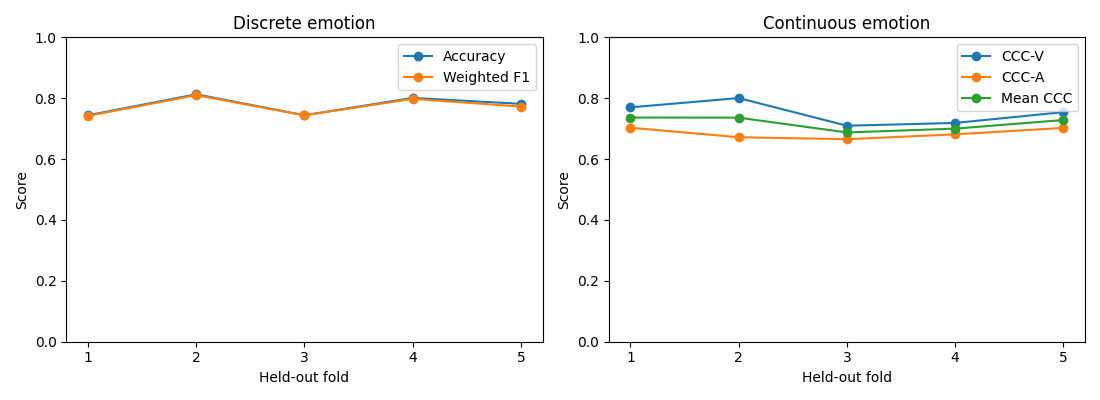

In [18]:
FIGURES = OUT / "figures"
FIGURES.mkdir(exist_ok=True)
fold_numbers = np.arange(1, 6)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for key, label in [("accuracy", "Accuracy"), ("weighted_f1", "Weighted F1")]:
    axes[0].plot(fold_numbers, [r[key] for r in independent_rows], marker="o", label=label)
for key, label in [("ccc_valence", "CCC-V"), ("ccc_arousal", "CCC-A"), ("mean_ccc", "Mean CCC")]:
    axes[1].plot(fold_numbers, [r[key] for r in independent_rows], marker="o", label=label)
for ax, title in zip(axes, ["Discrete emotion", "Continuous emotion"]):
    ax.set(title=title, xlabel="Held-out fold", ylabel="Score", ylim=(0, 1), xticks=fold_numbers)
    ax.legend()
fig.tight_layout()
for extension in ("png", "pdf"):
    fig.savefig(FIGURES / f"fold_scores.{extension}")
plt.close(fig)
display(Image(filename=str(FIGURES / "fold_scores.png")))


## 6-2. 예시 대화의 정서가·각성도 정답·예측

4단계에서 사전에 정한 동일 대화의 결과를 발화 순서로 표시한다.
점은 발화 단위 값이고 연결선은 순서를 보여주기 위한 시각적 보조다. 프레임별 정답이나 보간한 연속 주석이 아니다.
범위 밖 정답은 그래프 채점 대상으로 사용하지 않도록 마스킹한다.

**확인:** 정답과 예측이 항상 같게 보이도록 수정하거나 좋은 구간만 고르지 않는다. 전체 예시 대화를 표시한다.


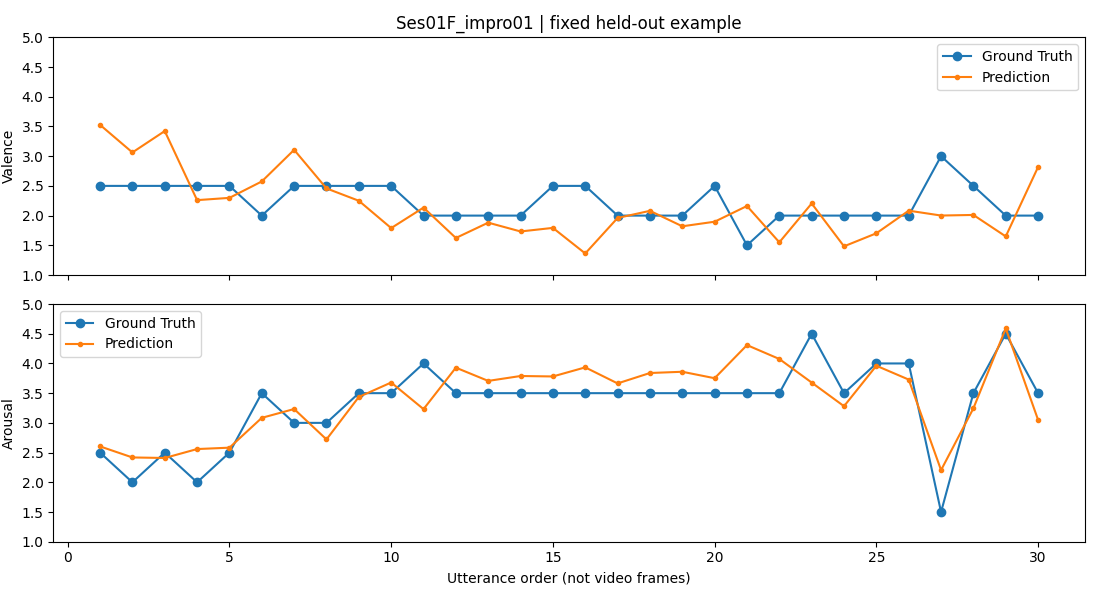

In [19]:
valid = ((example_va_targets >= 1) & (example_va_targets <= 5)).all(1)
truth = example_va_targets.astype(float).copy()
truth[~valid] = np.nan
utterance_order = np.arange(1, len(example_ids) + 1)
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for dimension, (ax, title) in enumerate(zip(axes, ["Valence", "Arousal"])):
    ax.plot(utterance_order, truth[:, dimension], marker="o", label="Ground Truth")
    ax.plot(utterance_order, example_va_predictions[:, dimension], marker=".", label="Prediction")
    ax.set(ylabel=title, ylim=(1, 5))
    ax.legend()
axes[0].set_title(EXAMPLE_DIALOGUE + " | fixed held-out example")
axes[1].set_xlabel("Utterance order (not video frames)")
fig.tight_layout()
for extension in ("png", "pdf"):
    fig.savefig(FIGURES / f"example_va.{extension}")
plt.close(fig)
display(Image(filename=str(FIGURES / "example_va.png")))


# 7. 독립 검증과 결과 보존
## 7-1. 설명용 추론과 전체 평가의 예측 일치 확인

**실행 내용:** 4단계에서 직접 계산한 예시 대화 예측이 전체 평가 결과의 동일 발화 예측과 일치하는지 확인한다.
설명 셀에서 생긴 전처리·가중치 연결 오류가 없는지 확인하는 단계다.

**확인:** 분류·V/A 모두 일치해야 한다. 이 검사는 예시 대화의 모델 선택을 바꾸지 않는다.


In [20]:
example_check = {}
for task, example_prediction in [("classification", example_class_predictions), ("va", example_va_predictions)]:
    with np.load(OUT / f"{task}_fold{EXAMPLE_FOLD}.npz", allow_pickle=False) as data:
        lookup = {uid: i for i, uid in enumerate(data["ids"])}
        positions = [lookup[uid] for uid in example_ids]
        full_prediction = data["predictions"][positions]
        difference = float(np.abs(full_prediction - example_prediction).max())
        assert np.allclose(full_prediction, example_prediction, atol=1e-6, rtol=0)
        example_check[task] = {"passed": True, "max_abs_difference": difference}
show_table([{"과제": task, "일치": value["passed"], "최대 절대 차이": value["max_abs_difference"]} for task, value in example_check.items()])
demo.write(OUT / "notebook_example_audit.json", example_check)


과제,일치,최대 절대 차이
classification,True,0.0
va,True,0.0


## 7-2. 전체 저장 예측의 독립 감사

### 함수 `audit_demo.audit`
- **기능:** 실제 저장 예측을 독립적으로 채점하고 원래 확정된 예측과 대조한다. ID·정답·채점 마스크·전체 OOF 중복 여부도 검사한다.
- **입력 인자:** `output` — 이번 실행 결과 폴더 `OUT`.
- **반환값:** `audit_result` — 통과 여부와 폴드별 수치 차이. `independent_audit.json`도 저장한다.

같은 저장 예측에서 다시 계산한 지표의 허용 오차는 `1e-10`이다.
이전에 GPU로 계산한 예측과 현재 CPU 예측의 비교에는 32비트 부동소수점 연산 차이를 고려해 최대 절대 차이 `1e-4`를 적용하며,
분류 클래스 결정은 정확히 일치해야 한다. 허용 오차는 실행 후 점수에 맞춰 바꾸지 않는다.

**확인:** 10개 폴드와 10,039개 비교 행이 `PASS`로 출력되어야 한다.


In [21]:
audit_result = audit_demo.audit(OUT)
assert audit_result["passed"]
show_table([{"독립 검증": audit_result["passed"], "비교 발화 수": audit_result["comparison_rows"],
             "과거 예측 대비 최대 절대 차이": audit_result["max_abs_prediction_difference"]}])


PASS | 10 folds | 10039 comparison rows | max prediction difference 1.1920929e-06


독립 검증,비교 발화 수,과거 예측 대비 최대 절대 차이
True,10039,1.1920928955078125e-06


## 7-3. 전체 정답 비교표와 결과 파일 확인

`utterance_comparison.csv`에는 전체 10,039개 발화의 이산·연속 정답과 예측, 채점 여부가 포함된다.
`report.html`은 폴드·발화 ID·텍스트를 검색할 수 있는 비교 화면이다. 노트북을 저장하면 셀 아래 출력도 함께 보존된다.

| 보존 파일 | 내용 |
|---|---|
| `summary.json`, `summary.txt`, `fold_metrics.csv` | 전체 지표와 폴드별 점수 |
| `classification_fold*.npz`, `va_fold*.npz`, `*_oof.npz` | 이번 실행 예측, 정답, 발화 ID, 채점 마스크 |
| `utterance_comparison.csv`, `report.html` | 전체 발화의 정답·예측 비교 |
| `figures/` | 폴드별 성능과 예시 V/A 그래프 PNG/PDF |
| `preflight.json`, `notebook_example_audit.json`, `independent_audit.json` | 파일·예시 추론·전체 채점의 검증 결과 |

**확인:** 아래 출력 경로의 폴더 전체를 보존한다. 표본 수가 적은 혐오와 채점 제외 발화의 존재도 함께 보고한다.


In [22]:
with (OUT / "utterance_comparison.csv").open(encoding="utf-8-sig", newline="") as f:
    comparison_rows = list(csv.DictReader(f))
assert len(comparison_rows) == 10039
show_table(comparison_rows, columns=["fold", "utterance_id", "original_emotion", "predicted_emotion_ko", "classification_valid", "gt_valence", "pred_valence", "gt_arousal", "pred_arousal", "va_valid"], limit=10)
print("결과 폴더:", OUT)
print("전체 비교 화면:", OUT / "report.html")
print("전체 비교표:", OUT / "utterance_comparison.csv")
print("완료: 학습 없이 실제 추론 및 독립 채점까지 수행했습니다.")


fold,utterance_id,original_emotion,predicted_emotion_ko,classification_valid,gt_valence,pred_valence,gt_arousal,pred_arousal,va_valid
1,Ses01F_impro01_F000,neu,중립,True,2.5,3.5269718170166016,2.5,2.6039226055145264,True
1,Ses01F_impro01_F001,neu,중립,True,2.5,3.422826051712036,2.5,2.4091248512268066,True
1,Ses01F_impro01_F002,neu,중립,True,2.5,2.298638105392456,2.5,2.582813024520874,True
1,Ses01F_impro01_F003,xxx,중립,False,2.5,3.1068170070648193,3.0,3.2330474853515625,True
1,Ses01F_impro01_F004,xxx,중립,False,2.5,2.4576995372772217,3.0,2.7215828895568848,True
1,Ses01F_impro01_F005,neu,분노,True,2.5,1.7897793054580688,3.5,3.679283618927002,True
1,Ses01F_impro01_F006,fru,분노,False,2.0,1.8812352418899536,3.5,3.7062206268310547,True
1,Ses01F_impro01_F007,fru,분노,False,2.5,1.793341875076294,3.5,3.781114101409912,True
1,Ses01F_impro01_F008,fru,분노,False,2.0,1.9604259729385376,3.5,3.6640632152557373,True
1,Ses01F_impro01_F009,fru,분노,False,2.0,1.8201802968978882,3.5,3.860114097595215,True


전체 10,039행 중 앞 10행 표시
결과 폴더: /tmp/iemocap_notebook_nspiyo1w/IEMOCAP_Official_Demo/results/notebook_20261111_111733_564998
전체 비교 화면: /tmp/iemocap_notebook_nspiyo1w/IEMOCAP_Official_Demo/results/notebook_20261111_111733_564998/report.html
전체 비교표: /tmp/iemocap_notebook_nspiyo1w/IEMOCAP_Official_Demo/results/notebook_20261111_111733_564998/utterance_comparison.csv
완료: 학습 없이 실제 추론 및 독립 채점까지 수행했습니다.


# 8. 현장 설명 문구와 해석 범위

> 학습이 완료된 이산 감정 분류 모델과 연속 감정 회귀 모델의 폴드별 가중치를 불러옵니다.
> IEMOCAP의 5개 세션으로 구성한 5겹 교차검증 평가에서 각 폴드의 학습·개발에 사용하지 않은 시험 세션의 멀티모달 특징을 입력합니다.
> 예측 감정 클래스와 원본 감정 라벨을 비교해 가중 F1을 산출하고, 예측 정서가·각성도와 원본 발화별 주석을 비교해 각 차원의 CCC 및 평균 CCC를 산출합니다.
> 현장에서는 재학습이나 모델 선택 없이 추론과 채점만 수행합니다.

이 결과는 **IEMOCAP 통제 환경의 발화 단위 예비 검증**이다. 자체 수집 자료의 어노테이션 성능, 실환경,
프레임 단위 연속 감정 검증, 새로운 자료를 이용한 독립 시험 또는 기관 인증 완료로 표현하지 않는다.
대화 내부 양방향 문맥을 사용하며 실시간 인과 추론을 검증한 결과도 아니다.

분류와 회귀는 별도 학습 모델이며 정답 표본 수가 다르다. 이산·연속 결과를 같은 표에서 보여주는 것은 발화 ID를 이용한 연결이며,
공동 멀티태스크 학습이나 모델 예측을 정답으로 삼은 자체 어노테이션 검증을 의미하지 않는다.
